# Maize cleaning from the team full database

This notebook reads only the private team_data_full_v1.duckdb. It covers all countries and years with eligible maize fields in that database.

The database already contains two clear monthly Sentinel-2 products: monthly_clearest (one image) and monthly_median (the median of clear images). The cleaning proposal keeps the team's official eligible, unlocked fields and spatial folds; aligns the two products on exactly the same season months; preserves missing months; and summarizes each field-season. The two matched representations can then be compared with the same basic model. Yield never determines image availability.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/team_data_full_v1.duckdb").is_file()), None)
assert ROOT is not None, "Place team_data_full_v1.duckdb in this repository's ignored data folder"
DB = ROOT/"data/team_data_full_v1.duckdb"
OUT = ROOT/"data/clean/allen_model_ready.parquet"
BANDS = ["b02","b03","b04","b05","b06","b07","b08","b8a","b11","b12"]
con = duckdb.connect(str(DB), read_only=True)
print("Input: data/team_data_full_v1.duckdb (read only)")
print("Output: data/clean/allen_model_ready.parquet")

Input: data/team_data_full_v1.duckdb (read only)
Output: data/clean/allen_model_ready.parquet


## 1. Labels and official spatial folds

Show every maize country and year, including sources with no eligible rows. The team database supplies the keep decision, spatial fold, locked status and 2 km gap flags. The model handoff contains only kept, unlocked fields in folds 1 through 4. Fold 0 and other locked fields are excluded. No yield values are modified.

In [2]:
inventory = con.execute("""
    SELECT l.release,l.country_iso3,l.season_year,
           count(*) AS maize_rows,
           count(*) FILTER(WHERE l.keep) AS eligible,
           count(*) FILTER(WHERE l.keep AND NOT f.locked
               AND f.fold BETWEEN 1 AND 4) AS development
    FROM labels l LEFT JOIN folds_all f USING(release,field_season_id)
    WHERE l.crop='maize'
    GROUP BY 1,2,3 ORDER BY 1,2,3
""").df()
print(inventory.to_string(index=False))
development = con.execute("""
    SELECT l.release,l.field_season_id,l.country_iso3,l.data_set,
           l.season_year,l.yield_t_ha,l.label_status,l.strict,
           l.geometry_type,l.location_quality,
           f.fold,f.locked,f.gap_1,f.gap_2,f.gap_3,f.gap_4
    FROM labels l JOIN folds_all f USING(release,field_season_id)
    WHERE l.crop='maize' AND l.keep AND NOT f.locked
      AND f.fold BETWEEN 1 AND 4
""").df()
assert len(development)==25579
assert not development.duplicated(["release","field_season_id"]).any()
assert development.yield_t_ha.notna().all()
print("Development fields:",len(development))
print("Countries with development fields:",development.country_iso3.nunique())
con.register("development",development[["release","field_season_id"]])

            release country_iso3  season_year  maize_rows  eligible  development
passarchive_oaf5_v1          BDI         2015         610         0            0
passarchive_oaf5_v1          BDI         2016        1383         0            0
passarchive_oaf5_v1          BDI         2017        1430      1052          831
passarchive_oaf5_v1          BDI         2019        1686         0            0
passarchive_oaf5_v1          BDI         2020        1268         0            0
passarchive_oaf5_v1          NGA         2022         115         0            0
passarchive_oaf5_v1          RWA         2016         845       476          307
passarchive_oaf5_v1          RWA         2017         795         0            0
passarchive_oaf5_v1          RWA         2018        1860         0            0
passarchive_oaf5_v1          RWA         2019        1542       201          169
passarchive_oaf5_v1          RWA         2020        2163       573          491
passarchive_oaf5_v1         

## 2. Align the two existing monthly products

The monthly_clearest table defines the season-month calendar. The monthly_median table has values where at least one clear pass exists. Use this_season for yield prediction. A month enters both arms only when the clearest image is marked clear and both tables provide all ten bands. This matches their field and month coverage. The source database has no full candidate-scene archive, so this notebook does not re-run any top-15 image selection.

In [3]:
band_sql = ", ".join(
    f"c.{b} AS clearest_{b}, m.{b} AS median_{b}" for b in BANDS)
monthly = con.execute(f"""
    SELECT c.release,c.field_season_id,c.season_month,c.clear,m.n_clear,
           {band_sql}
    FROM monthly_clearest c
    JOIN development d USING(release,field_season_id)
    LEFT JOIN monthly_median m
      ON m.release=c.release AND m.field_season_id=c.field_season_id
     AND m.which_year=c.which_year AND m.season_month=c.season_month
    WHERE c.which_year='this_season'
""").df()
assert not monthly.duplicated(["release","field_season_id","season_month"]).any()
clear_ok = monthly["clear"].fillna(False).copy()
median_ok = monthly.n_clear.notna().copy()
for band in BANDS:
    clear_ok &= monthly[f"clearest_{band}"].notna()
    median_ok &= monthly[f"median_{band}"].notna()
monthly["common_valid"] = clear_ok & median_ok
print("Scheduled months:",len(monthly))
print("Months usable in both arms:",int(monthly.common_valid.sum()))
print("Clear/median availability disagreements:",
      int((monthly["clear"].fillna(False)!=monthly.n_clear.notna()).sum()))
valid = monthly.loc[monthly.common_valid]
for arm in ("clearest","median"):
    outside = np.zeros(len(valid),dtype=bool)
    for band in BANDS:
        outside |= ~valid[f"{arm}_{band}"].between(0,1).to_numpy()
    print(arm,"months with any reflectance outside [0,1]:",int(outside.sum()))
con.close()

Scheduled months: 211094
Months usable in both arms: 203026
Clear/median availability disagreements: 0
clearest months with any reflectance outside [0,1]: 8
median months with any reflectance outside [0,1]: 3


## 3. Make the two matched season summaries

For each field-season, average the ten bands across usable months and summarize NDVI. Retain the number of scheduled months, observed months and supporting clear passes. Values outside the nominal reflectance range are reported above but are not silently clipped or removed. Months without an image stay missing for training-fold imputation.

In [4]:
KEY = ["release","field_season_id"]
def summarize(arm):
    frame = monthly[KEY+["season_month","n_clear","common_valid"]].copy()
    for band in BANDS:
        frame[band] = monthly[f"{arm}_{band}"].where(monthly.common_valid)
    frame["ndvi"] = (frame.b08-frame.b04)/(frame.b08+frame.b04).replace(0,np.nan)
    frame["usable_passes"] = frame.n_clear.where(frame.common_valid).fillna(0)
    fields = {f"{band}_mean":(band,"mean") for band in BANDS}
    out = frame.groupby(KEY).agg(
        months_expected=("season_month","size"),
        months_observed=("ndvi","count"),
        clear_passes=("usable_passes","sum"),
        ndvi_mean=("ndvi","mean"),ndvi_max=("ndvi","max"),
        **fields).reset_index()
    out["coverage_fraction"] = out.months_observed/out.months_expected
    return out

parts = []
for arm in ("clearest","median"):
    part = development.merge(summarize(arm),on=KEY,how="left",
                             validate="one_to_one")
    part["cleaning_arm"] = arm
    for name in ("months_expected","months_observed","clear_passes"):
        part[name] = part[name].fillna(0)
    parts.append(part)
ready = pd.concat(parts,ignore_index=True)
assert len(ready)==2*len(development)
assert not ready.duplicated(KEY+["cleaning_arm"]).any()
print("Matched rows:",len(ready))
print(ready.groupby("cleaning_arm")[["months_observed","coverage_fraction"]]
      .mean().round(3).to_string())

Matched rows: 51158
              months_observed  coverage_fraction
cleaning_arm                                    
clearest                7.937               0.96
median                  7.937               0.96


              fields  mean_months  zero_months
country_iso3                                  
BDI              831         5.54            0
KEN            15315         7.84            1
MWI             2011         8.66            0
RWA              967         5.37            4
TZA             1579         8.47            0
UGA              196         7.83            0
ZMB             1035         8.52            0
ZWE             3645         8.78            0


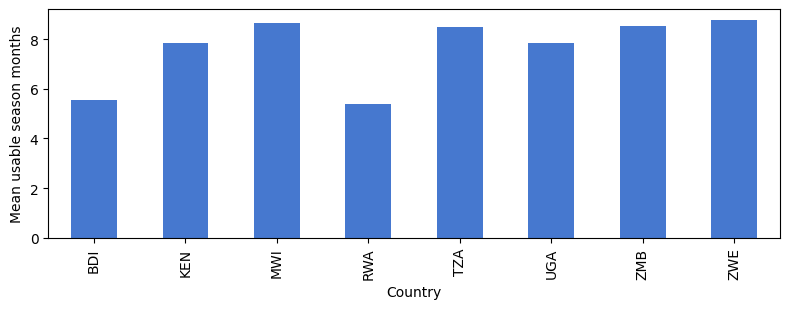

In [5]:
coverage = (ready.loc[ready.cleaning_arm=="median"]
            .groupby("country_iso3").agg(
                fields=("field_season_id","size"),
                mean_months=("months_observed","mean"),
                zero_months=("months_observed",lambda s:(s==0).sum()))
            .sort_index())
print(coverage.round(2).to_string())
ax = coverage.mean_months.plot.bar(figsize=(8,3.2),color="#4678cf")
ax.set_ylabel("Mean usable season months")
ax.set_xlabel("Country")
plt.tight_layout()
plt.show()

## 4. Verify and export

The two arms must contain the same field IDs and month coverage. Keep the official folds and gaps attached. Filter by cleaning_arm before fitting a model. The target is yield_t_ha. Identifiers, target, labels, folds, locks and gaps are metadata; remove them from model predictors. Fit imputation and scaling on the training rows inside each spatial fold. This notebook does not choose a winning method.

In [6]:
wide = ready.pivot(index=KEY,columns="cleaning_arm",
                   values=["months_expected","months_observed"])
assert (wide[("months_expected","median")]==wide[("months_expected","clearest")]).all()
assert (wide[("months_observed","median")]==wide[("months_observed","clearest")]).all()
assert ready.fold.between(1,4).all() and not ready.locked.any()
assert ready.country_iso3.nunique()==8
OUT.parent.mkdir(parents=True,exist_ok=True)
ready.to_parquet(OUT,index=False)
print("Saved:",OUT.relative_to(ROOT))
print("Fields:",len(development),"Rows:",len(ready),
      "Countries:",ready.country_iso3.nunique())
print("No-image fields:",int((wide[("months_observed","median")]==0).sum()))

Saved: data\clean\allen_model_ready.parquet
Fields: 25579 Rows: 51158 Countries: 8
No-image fields: 5


### Limits

The source image products were already quality-screened upstream. The full database does not include every raw pass or field pixel, so the original top-15 selection cannot be reconstructed from this file. The two arms use the same records and folds; any predictive advantage still needs an identical-model evaluation. The generated Parquet stays in ignored data/clean/. See the README in this folder for the data handoff.